<a href="https://colab.research.google.com/github/Joao-Barbi/streaming_churn/blob/master/Estat%C3%ADtica_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Análise de Funil de Conversão do Onboarding

Agora vamos carregar e pré-processar o arquivo `funil_eventos.csv` para a análise do funil.

In [65]:
# Caminho do arquivo funil_eventos.csv
caminho_funil_eventos = os.path.join(caminho_pasta, 'funil_eventos.csv')

# Carregar o arquivo funil_eventos.csv
try:
    df_funil = pd.read_csv(caminho_funil_eventos)
    print(f"Arquivo '{os.path.basename(caminho_funil_eventos)}' carregado com sucesso.")
except FileNotFoundError:
    print(f"Erro: O arquivo '{os.path.basename(caminho_funil_eventos)}' não foi encontrado em '{caminho_pasta}'.")
    df_funil = pd.DataFrame() # Criar DataFrame vazio em caso de erro

# Remover duplicatas
if not df_funil.empty:
    linhas_antes = df_funil.shape[0]
    df_funil.drop_duplicates(inplace=True)
    linhas_depois = df_funil.shape[0]
    print(f"Removidas {linhas_antes - linhas_depois} linhas duplicadas.")

    print("\nPrimeiras 5 linhas do DataFrame `df_funil` após carregamento e remoção de duplicatas:")
    display(df_funil.head())
else:
    print("Não foi possível carregar o DataFrame de funil.")

Arquivo 'funil_eventos.csv' carregado com sucesso.
Removidas 50 linhas duplicadas.

Primeiras 5 linhas do DataFrame `df_funil` após carregamento e remoção de duplicatas:


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula


### Processamento e Análise do Funil de Conversão

Vamos agora padronizar a coluna `etapa` e construir a análise do funil de conversão.

Valores únicos da coluna 'etapa' após padronização:


array(['assistiu_1a_aula', 'criou_conta', 'visitou_site', 'renovou',
       'assinou_plano'], dtype=object)


=== Tabela de Funil de Conversão ===


,usuarios,conversao_anterior,conversao_topo
etapa,,,
visitou_site,5000,100.000000,100.00
criou_conta,3377,67.540000,67.54
assistiu_1a_aula,2698,79.893397,53.96
assinou_plano,1066,39.510749,21.32
renovou,695,65.196998,13.90



O maior gargalo do funil é na etapa 'assinou_plano' com uma taxa de conversão de 39.51% da etapa anterior.


/tmp/ipykernel_490/4215817548.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='usuarios', y='etapa', data=plot_data.sort_values(by='usuarios', ascending=True),


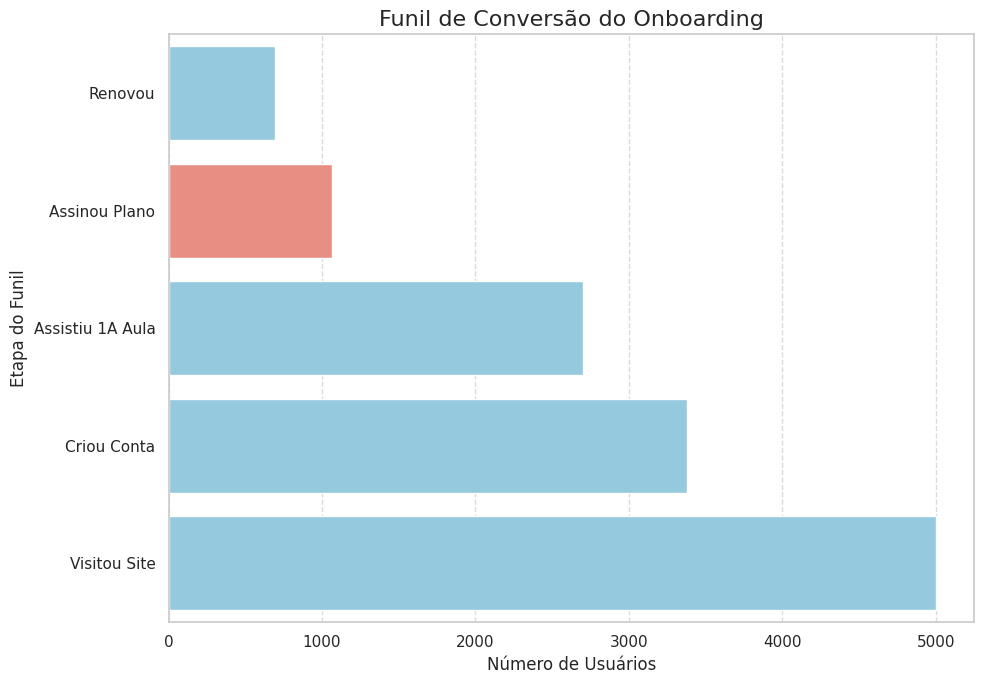

In [66]:
# 1. Padronizar a coluna 'etapa'
def padronizar_etapa(etapa):
    if pd.isna(etapa):
        return etapa
    return str(etapa).lower().replace(' ', '_').strip()

df_funil['etapa'] = df_funil['etapa'].apply(padronizar_etapa)
print("Valores únicos da coluna 'etapa' após padronização:")
display(df_funil['etapa'].unique())

# 2. Definir a ordem do funil
ordem_funil = [
    'visitou_site',
    'criou_conta',
    'assistiu_1a_aula',
    'assinou_plano',
    'renovou'
]

# Filtrar apenas as etapas do funil na ordem definida
df_funil_ordenado = df_funil[df_funil['etapa'].isin(ordem_funil)].copy()

# Contar clientes únicos por etapa
funil_counts = df_funil_ordenado.groupby('etapa')['cliente_id'].nunique().reindex(ordem_funil)

# 3. Montar a tabela do funil
tabela_funil = pd.DataFrame(funil_counts)
tabela_funil.columns = ['usuarios']

# Taxa de conversão da etapa anterior
tabela_funil['conversao_anterior'] = (tabela_funil['usuarios'] / tabela_funil['usuarios'].shift(1) * 100).fillna(100)

# Taxa de conversão em relação ao topo do funil
tabela_funil['conversao_topo'] = (tabela_funil['usuarios'] / tabela_funil['usuarios'].iloc[0] * 100).fillna(100)

print("\n=== Tabela de Funil de Conversão ===")
display(tabela_funil)

# 4. Identificar a etapa com a maior queda de conversão (maior gargalo)
# A maior queda é a menor taxa de conversao_anterior (excluindo a primeira etapa que é 100%)
maior_queda_idx = tabela_funil['conversao_anterior'][1:].idxmin()
maior_queda_valor = tabela_funil['conversao_anterior'][1:].min()

print(f"\nO maior gargalo do funil é na etapa '{maior_queda_idx}' com uma taxa de conversão de {maior_queda_valor:.2f}% da etapa anterior.")

# 5. Plotar o gráfico de Pareto

# Preparar dados para o gráfico (etapas e número de usuários)
plot_data = tabela_funil[['usuarios']].reset_index()
plot_data['etapa'] = plot_data['etapa'].str.replace('_', ' ').str.title()

# Definir cores para o gráfico, destacando o gargalo
colors = ['skyblue'] * len(plot_data)
if maior_queda_idx:
    gargalo_index = ordem_funil.index(maior_queda_idx)
    colors[gargalo_index] = 'salmon' # Cor para o gargalo

plt.figure(figsize=(10, 7))
sns.barplot(x='usuarios', y='etapa', data=plot_data.sort_values(by='usuarios', ascending=True),
            palette=colors[::-1], orient='h') # Inverter para exibir o funil corretamente

plt.title('Funil de Conversão do Onboarding', fontsize=16)
plt.xlabel('Número de Usuários', fontsize=12)
plt.ylabel('Etapa do Funil', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()